# Divvy Bike Share: Rider Classification Using Machine Learning

**MSA 8010 – Data Programming**

### Project Overview

This analysis investigates whether historical Divvy bike-sharing trip patterns can be used to classify trips as belonging to casual riders or annual members. Using a cleaned dataset containing approximately 15.8 million trips from 2024 through 2026, the goal is to identify behavioral patterns associated with rider membership type and evaluate how effectively machine-learning models can distinguish between the two groups.

The analysis begins with data exploration and feature engineering, followed by the development of Logistic Regression and Random Forest classification models. Several experiments are conducted to examine the effects of training sample size, classification thresholds, and model selection on predictive performance.

Data from 2024 is used for training, 2025 for validation, and 2026 for out-of-time testing. Model performance is assessed using accuracy, precision, recall, F1-score, and confusion matrices, with particular emphasis on correctly identifying casual-rider trips.

The findings aim to provide insight into the relationship between riding behavior and membership type while identifying potential applications and limitations of machine learning in supporting Divvy's membership-growth strategy.

In [34]:
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt
import pyarrow as pa
import sys

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
   accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.ensemble import RandomForestClassifier

In [3]:
print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("Pyarrow:", pa.__version__)

Python: c:\Users\deanc\AppData\Local\Programs\Python\Python312\python.exe
Pandas: 3.0.6
Pyarrow: 26.0.1


In [4]:
columns = [
    "member_casual",
    "rideable_type",
    "started_at",
    "ended_at"
]

In [ ]:
df = pd.read_parquet(
    "data/divvy_clean_2024_2026.parquet", 
    columns=columns
)
df.shape


(15851351, 4)

In [6]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 15851351 entries, 0 to 15851350
Data columns (total 4 columns):
 #   Column         Dtype         
---  ------         -----         
 0   member_casual  str           
 1   rideable_type  str           
 2   started_at     datetime64[ns]
 3   ended_at       datetime64[ns]
dtypes: datetime64[ns](2), str(2)
memory usage: 765.6 MB


In [7]:
df["member_casual"].value_counts()

member_casual
member    10126399
casual     5724952
Name: count, dtype: int64

In [10]:
df["member_casual"].value_counts(normalize=True) * 100

member_casual
member    63.883507
casual    36.116493
Name: proportion, dtype: float64

In [11]:
df["year"] = df["started_at"].dt.year
df["year"].value_counts().sort_index()

year
2024    5707597
2025    5389264
2026    4754490
Name: count, dtype: int64

# Feature Engineering

In [12]:
# Ensure timestamps are datetime objects
df["started_at"] = pd.to_datetime(df["started_at"])
df["ended_at"] = pd.to_datetime(df["ended_at"])

# Calculate trip duration in minutes
df["ride_length"] = (
    df["ended_at"] - df["started_at"]
).dt.total_seconds() / 60

# Extract time-related features
df["hour"] = df["started_at"].dt.hour
df["day_of_week"] = df["started_at"].dt.dayofweek
df["month"] = df["started_at"].dt.month

# Identify weekend trips
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

# Inspect engineered features
df[
    [
        "member_casual",
        "ride_length",
        "hour",
        "day_of_week",
        "month",
        "is_weekend"
    ]
].head(20)

,member_casual,ride_length,hour,day_of_week,month,is_weekend
0,member,7.533333,15,4,1,0
1,member,7.216667,15,0,1,0
2,member,8.000000,12,5,1,1
3,member,29.816667,16,0,1,0
4,member,26.200000,5,2,1,0
5,member,8.650000,11,6,1,1
6,member,8.900000,14,4,1,0
7,member,8.183333,18,3,1,0
8,member,10.150000,14,0,1,0
9,member,8.950000,19,2,1,0


In [13]:
print("Missing values:")
print(
    df[
        ["member_casual", "rideable_type", "ride_length",
         "hour", "day_of_week", "month"]
    ].isna().sum()
)

print("\nRide length statistics:")
print(df["ride_length"].describe())

print("\nNonpositive durations:")
print((df["ride_length"] <= 0).sum())

print("\nTrips longer than 24 hours:")
print((df["ride_length"] > 1440).sum())


Missing values:
member_casual    0
rideable_type    0
ride_length      0
hour             0
day_of_week      0
month            0
dtype: int64

Ride length statistics:
count    1.585135e+07
mean     1.423908e+01
std      1.529445e+01
min      1.000000e+00
25%      5.720817e+00
50%      9.762350e+00
75%      1.696974e+01
max      1.799989e+02
Name: ride_length, dtype: float64

Nonpositive durations:
0

Trips longer than 24 hours:
0


In [14]:
df['member_casual'].value_counts()

member_casual
member    10126399
casual     5724952
Name: count, dtype: int64

In [15]:
df.loc[df['member_casual'] == 'casual', [
    'member_casual',
    'ride_length',
    'hour',
    'day_of_week',
    'month',
    'is_weekend'
]].head(10)
       

,member_casual,ride_length,hour,day_of_week,month,is_weekend
34,casual,23.566667,19,0,1,0
35,casual,20.616667,11,1,1,0
36,casual,23.916667,16,2,1,0
91,casual,14.750000,19,5,1,1
95,casual,16.716667,15,4,1,0
96,casual,12.933333,13,4,1,0
110,casual,16.183333,17,4,1,0
181,casual,4.316667,16,3,1,0
209,casual,4.050000,12,0,1,0
235,casual,114.333333,10,3,1,0


In [16]:
ride_comparison = (
    df.groupby("member_casual")["ride_length"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(ride_comparison)

,count,mean,median,std
member_casual,,,,
casual,5724952,18.47,11.90,20.39
member,10126399,11.85,8.81,10.73


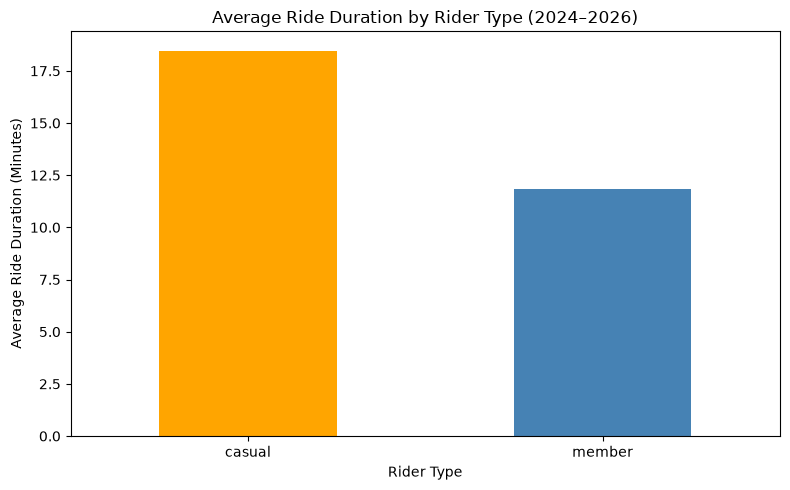

In [17]:
ride_comparison["mean"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["orange", "steelblue"]
)

plt.title("Average Ride Duration by Rider Type (2024–2026)")
plt.xlabel("Rider Type")
plt.ylabel("Average Ride Duration (Minutes)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# How To Split The Data
2024 Training Data |
2025 Validation Data |
2026 Test Data 

In [18]:
# Select relevant features
features = [
    "ride_length",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "rideable_type"
]

# Encode the target variable
# casual = 1, member = 0
df["target"] = (
    df["member_casual"] == "casual"
).astype("int8")

# Create separate datasets by year
train_df = df.loc[df["year"] == 2024, features + ["target"]]
val_df = df.loc[df["year"] == 2025, features + ["target"]]
test_df = df.loc[df["year"] == 2026, features + ["target"]]

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (5707597, 7)
Validation: (5389264, 7)
Testing: (4754490, 7)


In [19]:
year_distribution = pd.crosstab(
    df["year"],
    df["member_casual"],
    normalize="index"
) * 100

display(year_distribution.round(2))

member_casual,casual,member
year,,
2024,36.28,63.72
2025,35.42,64.58
2026,36.71,63.29


In [20]:
# Define sample sizes for our experiment
sample_sizes = [25000, 50000, 100000, 200000]

# Create reproducible nested training samples
train_pool = train_df.sample(
    n=max(sample_sizes),
    random_state=42
)

# Sort randomly so smaller samples are subsets of larger ones
train_pool = train_pool.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

training_samples = {}

for size in sample_sizes:
    training_samples[size] = train_pool.iloc[:size]

    print(
        f"Sample size: {size:,} | "
        f"Casual percentage: "
        f"{training_samples[size]['target'].mean() * 100:.2f}%"
    )

Sample size: 25,000 | Casual percentage: 36.62%
Sample size: 50,000 | Casual percentage: 36.48%
Sample size: 100,000 | Casual percentage: 36.63%
Sample size: 200,000 | Casual percentage: 36.48%


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

numeric_features = [
    "ride_length",
    "hour",
    "day_of_week",
    "month",
    "is_weekend"
]

categorical_features = ["rideable_type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [22]:
# Fixed validation sample from 2025
val_sample = val_df.sample(
    n=100000,
    random_state=42
)

X_val = val_sample[features]
y_val = val_sample["target"]

results = []
models = {}

for size, sample in training_samples.items():

    print(f"\nTraining model with {size:,} observations...")

    X_train = sample[features]
    y_train = sample["target"]

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(max_iter=1000)
            )
        ]
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    results.append({
        "Training Size": size,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred)
    })

    models[size] = model

results_df = pd.DataFrame(results)

display(results_df.round(4))


Training model with 25,000 observations...

Training model with 50,000 observations...

Training model with 100,000 observations...

Training model with 200,000 observations...


,Training Size,Accuracy,Precision,Recall,F1
0,25000,0.6735,0.6183,0.1948,0.2963
1,50000,0.6739,0.6192,0.1967,0.2986
2,100000,0.6737,0.6163,0.1988,0.3006
3,200000,0.6742,0.6241,0.1923,0.2940


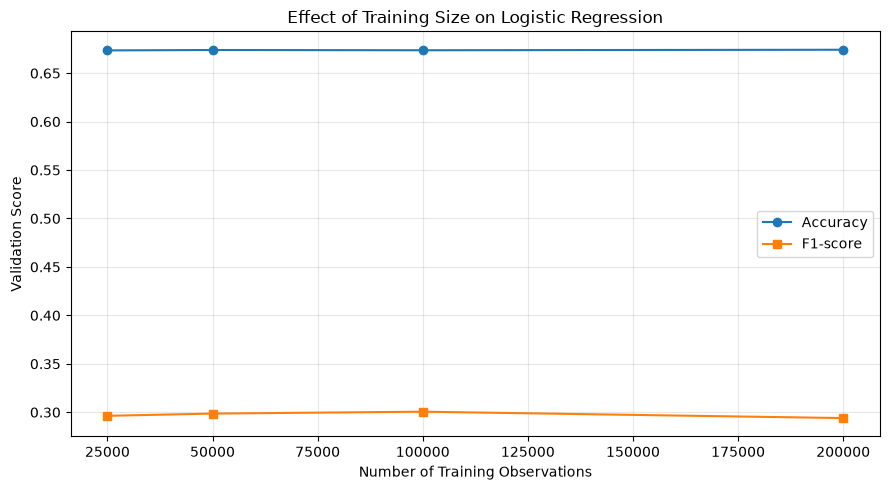

In [23]:
plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Training Size"],
    results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["Training Size"],
    results_df["F1"],
    marker="s",
    label="F1-score"
)

plt.xlabel("Number of Training Observations")
plt.ylabel("Validation Score")
plt.title("Effect of Training Size on Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Increasing the training sample from 25,000 to 200,000 observations produced minimal improvement in Logistic Regression performance. Consequently, the analysis shifted toward examining classification errors, decision thresholds, and alternative algorithms.

# First Experiment: Confusion Matrix for Casual and Member Riders

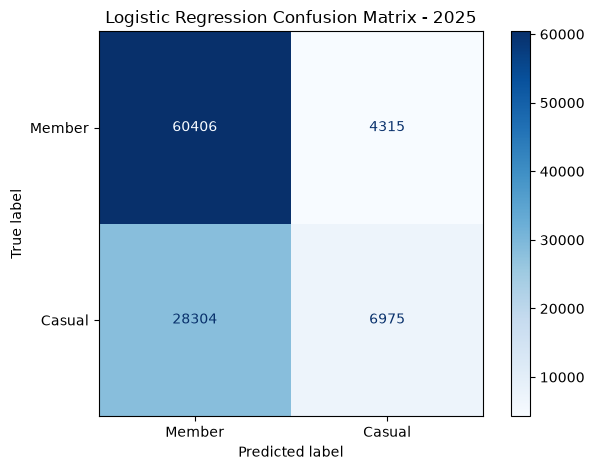

              precision    recall  f1-score   support

      Member       0.68      0.93      0.79     64721
      Casual       0.62      0.20      0.30     35279

    accuracy                           0.67    100000
   macro avg       0.65      0.57      0.54    100000
weighted avg       0.66      0.67      0.62    100000



In [24]:
# Select the best model based on F1-score
best_logistic = models[100000]

# Predict using the 2025 validation data
y_pred = best_logistic.predict(X_val)

# Calculate confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Member", "Casual"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression Confusion Matrix - 2025")
plt.tight_layout()
plt.show()

# Detailed classification metrics
print(
    classification_report(
        y_val,
        y_pred,
        target_names=["Member", "Casual"]
    )
)

This model isn't that effective at predicting casual riders. Let's try lowering the classification threshold to see if we can improve our recall for casual riders.

In [25]:
# Predicted probability of casual (class 1)
y_proba = best_logistic.predict_proba(X_val)[:, 1]

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    predictions = (y_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1
0,0.30,0.4209,0.7331,0.5347
1,0.35,0.4609,0.5591,0.5053
2,0.40,0.5080,0.4162,0.4575
3,0.45,0.5618,0.2850,0.3782
4,0.50,0.6178,0.1977,0.2996


We are able to increase recall by 53.54% by lowering the classification threshold. The tradeoff is that precision dropped by 19.69%. So, lowering the threshold to 30% will allow us to classify more trips as casual. 

# Second Experiment: Optimizing the Classification Threshold

In [26]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.15, 0.51, 0.01)

threshold_results = []

for threshold in thresholds:
    predictions = (y_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

best_row = threshold_df.loc[threshold_df["F1"].idxmax()]

print("Best threshold:", best_row["Threshold"])
print("Best F1-score:", round(best_row["F1"], 4))

display(threshold_df.sort_values("F1", ascending=False).head(10))

Best threshold: 0.27
Best F1-score: 0.5387


,Threshold,Precision,Recall,F1
12,0.27,0.393900,0.851923,0.538717
13,0.28,0.402649,0.812523,0.538462
11,0.26,0.385279,0.886987,0.537211
14,0.29,0.411668,0.772669,0.537150
10,0.25,0.377958,0.919187,0.535659
15,0.30,0.420862,0.733071,0.534731
9,0.24,0.370788,0.944726,0.532557
16,0.31,0.428429,0.693472,0.529643
8,0.23,0.364866,0.964285,0.529413
7,0.22,0.360568,0.979223,0.527062


Lowering the threshold to 0.27 proves to be the best approach since recall improved to 0.85! However, this comes at lower precision rate of 0.39. For logistic regression 0.27 is the best threshold. 

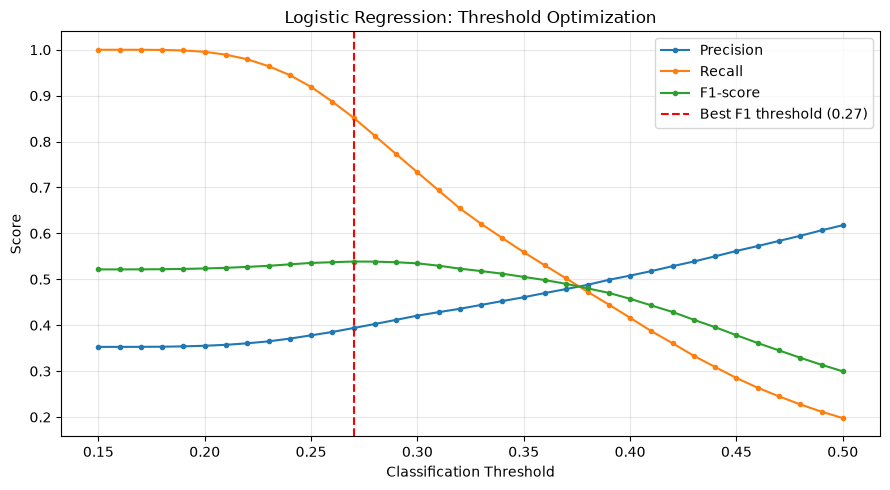

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker=".",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker=".",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker=".",
    label="F1-score"
)

plt.axvline(
    x=0.27,
    color="red",
    linestyle="--",
    label="Best F1 threshold (0.27)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression: Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

This graphs shows that as the threshold increases that recall decreases. The tradeoff here is with precision. As we increase the the threshold classification then precision increases while recall decreases significantly. 

# Third Experiment: Random Forest

In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use the same 100,000-record training sample
sample = training_samples[100000]

X_train = sample[features]
y_train = sample["target"]

# Create Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=12,
                min_samples_leaf=10,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict on the same 2025 validation sample
rf_pred = rf_model.predict(X_val)

print("Random Forest Results")
print("Accuracy:", round(accuracy_score(y_val, rf_pred), 4))
print("Precision:", round(precision_score(y_val, rf_pred), 4))
print("Recall:", round(recall_score(y_val, rf_pred), 4))
print("F1:", round(f1_score(y_val, rf_pred), 4))

Random Forest Results
Accuracy: 0.6824
Precision: 0.6215
Recall: 0.2554
F1: 0.362


The random forest actually performed better at the initial threshold of 50 compared to logistic regression. Let's modify the threshold to see if we can improve our results for random forest. 

# Fourth Experiment: Modify Threshold For Random Forest

In [30]:
# Get Random Forest predicted probabilities
rf_proba = rf_model.predict_proba(X_val)[:, 1]

# Evaluate different thresholds
rf_threshold_results = []

for threshold in np.arange(0.15, 0.51, 0.01):

    rf_predictions = (rf_proba >= threshold).astype(int)

    rf_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_val, rf_predictions),
        "Precision": precision_score(y_val, rf_predictions, zero_division=0),
        "Recall": recall_score(y_val, rf_predictions, zero_division=0),
        "F1": f1_score(y_val, rf_predictions, zero_division=0)
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

# Find best threshold based on F1
best_rf_row = rf_threshold_df.loc[
    rf_threshold_df["F1"].idxmax()
]

display(
    rf_threshold_df
    .sort_values("F1", ascending=False)
    .head(10)
)

print("Best RF threshold:", best_rf_row["Threshold"])
print("Best RF F1:", round(best_rf_row["F1"], 4))

,Threshold,Accuracy,Precision,Recall,F1
15,0.30,0.56458,0.435398,0.789280,0.561210
16,0.31,0.57816,0.443153,0.762890,0.560638
14,0.29,0.54928,0.427173,0.814110,0.560333
17,0.32,0.59030,0.450740,0.738031,0.559671
13,0.28,0.53533,0.420197,0.834916,0.559040
18,0.33,0.60175,0.458605,0.713796,0.558427
12,0.27,0.52215,0.414199,0.855636,0.558189
11,0.26,0.50622,0.407083,0.875450,0.555745
10,0.25,0.49134,0.401009,0.894895,0.553838
19,0.34,0.61379,0.467339,0.677740,0.553210


Best RF threshold: 0.3
Best RF F1: 0.5612


The random forest model has outperformed the tuned logistic regression model on the 2025 validation data. Moving forward for the 2026 analysis I will use Random Forest at 0.30 threshold. 

2026 Test Results
Accuracy: 0.5381
Precision: 0.4336
Recall: 0.8398
F1: 0.5719

Classification Report:
              precision    recall  f1-score   support

      Member       0.80      0.36      0.50     63269
      Casual       0.43      0.84      0.57     36731

    accuracy                           0.54    100000
   macro avg       0.61      0.60      0.54    100000
weighted avg       0.66      0.54      0.53    100000



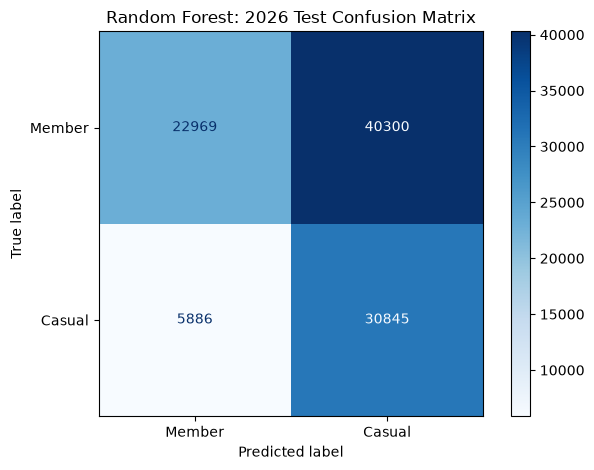

In [32]:
# Select a reproducible 2026 test sample
test_sample = test_df.sample(
    n=100000,
    random_state=42
)

X_test = test_sample[features]
y_test = test_sample["target"]

# Keep our selected 2025 validation threshold fixed
final_threshold = 0.30

# Predict casual rider probabilities
test_proba = rf_model.predict_proba(X_test)[:, 1]

# Convert probabilities to classifications
y_pred_2026 = (test_proba >= final_threshold).astype(int)

# Calculate performance metrics
print("2026 Test Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred_2026), 4))
print("Precision:", round(precision_score(y_test, y_pred_2026), 4))
print("Recall:", round(recall_score(y_test, y_pred_2026), 4))
print("F1:", round(f1_score(y_test, y_pred_2026), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_2026,
        target_names=["Member", "Casual"]
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_2026)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Member", "Casual"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest: 2026 Test Confusion Matrix")
plt.tight_layout()
plt.show()

,Actual,Predicted
Member,63.27,28.85
Casual,36.73,71.14


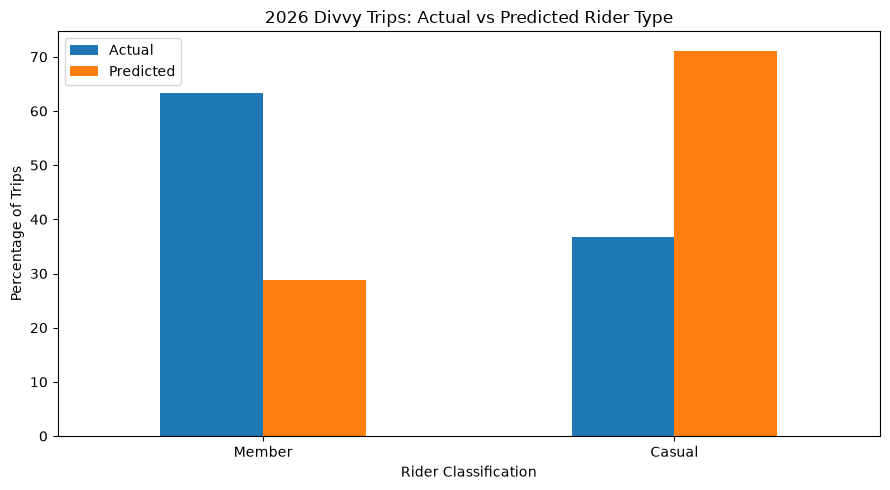

In [33]:
# Actual rider distribution
actual = pd.Series(y_test.to_numpy()).value_counts(
    normalize=True
) * 100

# Predicted rider distribution
predicted = pd.Series(y_pred_2026).value_counts(
    normalize=True
) * 100

# Build comparison table
comparison = pd.DataFrame({
    "Actual": actual,
    "Predicted": predicted
})

comparison.index = comparison.index.map({
    0: "Member",
    1: "Casual"
})

comparison = comparison.reindex(["Member", "Casual"])

display(comparison.round(2))

# Plot comparison
comparison.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("2026 Divvy Trips: Actual vs Predicted Rider Type")
plt.xlabel("Rider Classification")
plt.ylabel("Percentage of Trips")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [35]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Threshold": [0.27, 0.30],
    "Validation F1": [0.5387, 0.5612],
    "Validation Precision": [0.3939, 0.4354],
    "Validation Recall": [0.8519, 0.7893]
})

display(model_comparison)

,Model,Threshold,Validation F1,Validation Precision,Validation Recall
0,Logistic Regression,0.27,0.5387,0.3939,0.8519
1,Random Forest,0.30,0.5612,0.4354,0.7893


# Model Evaluation and Interpretation

The Random Forest model was selected based on its performance on the 2025 validation dataset, achieving an F1-score of 0.5612 for casual-rider classification at a decision threshold of 0.30.

When evaluated on 100,000 previously unseen observations from 2026, the model achieved an F1-score of 0.5719, precision of 0.4336, and recall of 0.8398 for casual riders.

Although the model identified approximately 84% of actual casual trips, its precision remained relatively low. The model predicted 71.14% of trips as casual, whereas only 36.73% were actually casual. This resulted in 40,300 member trips being incorrectly classified as casual.

These findings demonstrate a tradeoff between identifying casual trips and minimizing false positives. Lowering the classification threshold improved recall but reduced overall accuracy and resulted in substantial overprediction of the casual category.

The results suggest that riding duration, temporal patterns, and bicycle type provide some information about membership classification, but the selected model is not sufficiently reliable for direct operational deployment.

Future improvements could include additional behavioral features, alternative algorithms, probability calibration, and evaluation of different classification thresholds based on practical marketing objectives.